# TD 5 : classer des images

**BUT INFO3 Développeur IA, R5.C.08, IA5, Partie 1**
M. Sakkari, IUT de La Rochelle

> **À rendre :** les cellules « À vous » complétées, dans votre dépôt GitLab.

## Dans ce TD, on apprend à...
- **représenter une image** par des nombres, comme on l'a fait pour le texte et pour le son ;
- **classer** : entraîner un **perceptron** (un modèle de classification très simple, expliqué en partie 2) à reconnaître un chiffre écrit à la main, d'abord entre deux chiffres, puis entre les dix ;
- **lire les erreurs** du modèle avec une **matrice de confusion** (un tableau qui montre quels chiffres sont confondus avec quels autres) ;
- **comprendre ce que contient un modèle appris** : ses **paramètres**, c'est-à-dire des nombres réglés pendant l'entraînement.
## Les données
**Digits** (« chiffres ») : 1 797 petites images de chiffres écrits à la main, de 0 à 9. Chaque image est un carré de **8 × 8 pixels**. Ce jeu est fourni avec la bibliothèque scikit-learn et vient de l'UCI (*University of California, Irvine*).

Références : [`load_digits` (scikit-learn)](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html) ; [Optical Recognition of Handwritten Digits (UCI)](https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits).

> **Comment travailler :** une cellule « Démo » est déjà écrite, il faut la lancer et la lire. Une cellule « À vous » est à compléter : remplacez les `...` par votre code. **Exécutez les cellules dans l'ordre, de haut en bas.** Si vous redémarrez le noyau (le programme Python qui exécute les cellules), relancez d'abord la première cellule de code, celle qui charge les outils.

## Petit lexique avant de commencer

Ces mots reviennent dans tout le TD. Ils sont aussi expliqués au moment où on s'en sert.

| Mot | Ce que ça veut dire | Exemple |
|---|---|---|
| **Exemple** | une ligne du tableau de données : ici, une image | l'image n°100 |
| **Étiquette** (ou **vrai chiffre**) | la bonne réponse associée à un exemple | l'image n°100 a pour étiquette 4 |
| **Modèle** | un programme qui apprend à répondre à une question à partir d'exemples, au lieu d'être programmé avec des règles écrites à la main | un programme qui reconnaît le chiffre écrit sur une image |
| **Entraîner** (ou **apprendre**) | montrer des exemples au modèle pour qu'il ajuste ses **poids et son biais** (les nombres qu'il utilise pour calculer sa réponse, expliqués en partie 2) et fasse moins d'erreurs | on lui montre des images avec leur étiquette |
| **Époque** | un passage complet sur toutes les images d'apprentissage | avec 100 images, une époque = les 100 images vues une fois |
| **Prédire** (une **prédiction**) | donner la réponse du modèle pour une image | le modèle prédit « 7 » |
| **Classer** (la **classification**) | prédire la catégorie d'un exemple, parmi plusieurs possibles | 0, 1, 2... ou 9 |
| **Découpage** | la façon de répartir les images en plusieurs paquets avant l'entraînement. C'est un **choix**, pas une règle | 75 % pour apprendre et 25 % pour tester, ou 80 % / 20 %, ou 70 % pour apprendre, 20 % pour tester et 10 % pour la validation (dans ce TD : 75 % / 25 %) |
| **Jeu d'apprentissage** | les images sur lesquelles le modèle s'entraîne | dans ce TD : 75 % des images. C'est le cours et ses exercices |
| **Jeu de validation** | un paquet d'images, utilisé **avant le test** pour comparer plusieurs versions d'un même modèle (par exemple entraîné pendant 5, 10 ou 50 époques) et garder la meilleure. Il n'est pas utilisé dans ce TD | avec un découpage 70 % pour apprendre, 20 % pour tester et 10 % pour la validation : ce sont les 10 % de validation. C'est l'examen blanc : on s'en sert pour comparer les versions et garder la meilleure, alors que le jeu de test (l'examen final) reste caché |
| **Jeu de test** | les images cachées pendant l'entraînement. On les utilise **en dernier**, quand le modèle est appris et ses réglages choisis, pour mesurer sa précision. On ne s'en sert jamais pour changer le modèle | dans ce TD : 25 % des images. C'est l'examen final |
| **Précision** | la part des prédictions justes | 94 images bien classées sur 100 : précision de 94 % |

In [1]:
# Objectif : charger les outils et les images de chiffres.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

# load_digits charge les 1 797 images et leurs chiffres (aucun fichier à télécharger)
chiffres = load_digits()

images = chiffres.images       # les images sous forme de carrés 8 × 8
X = chiffres.data / 16.0       # les mêmes images, une image par ligne de 64 nombres
y = chiffres.target            # le vrai chiffre de chaque image (0 à 9)

# Un pixel vaut de 0 (blanc) à 16 (noir) : on divise par 16 pour avoir des valeurs entre 0 et 1
print("Images :", images.shape)
print("Tableau X :", X.shape, "(une ligne par image, une colonne par pixel)")
print("Nombre d'images de chaque chiffre :", np.bincount(y))

Images : (1797, 8, 8)
Tableau X : (1797, 64) (une ligne par image, une colonne par pixel)
Nombre d'images de chaque chiffre : [178 182 177 183 181 182 181 179 174 180]


# Partie 1 : Une image est un tableau de nombres

### Concept

Une image en noir et blanc est une grille de **pixels**. Chaque pixel est un nombre : ici, de **0** (blanc) à **16** (noir). Une image de 8 × 8 pixels est donc 64 nombres.

Pour l'utiliser comme les autres données du cours, on met ses 64 nombres **à plat, sur une seule ligne**. Une image devient alors une ligne d'un tableau `X` de 64 colonnes, comme un avis devenait une ligne de 500 colonnes (TD 3). Et `y` contient la réponse : le chiffre que l'image représente (rappel du TD 1 : `X` = ce qu'on utilise, `y` = ce qu'on cherche à prédire).

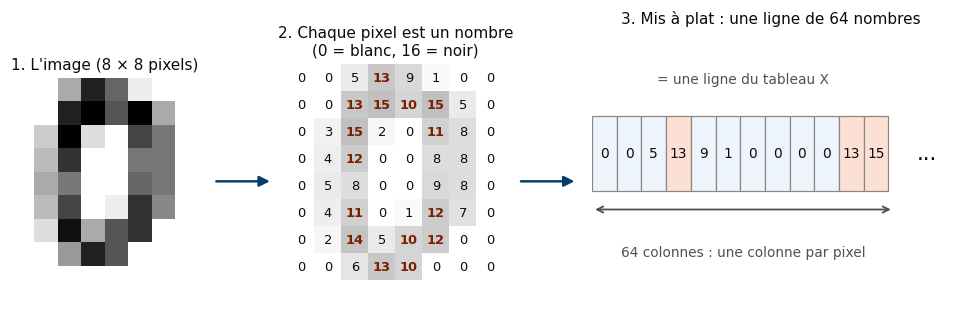

### Démo : la première image

Les 64 nombres de la première image, rangés en grille 8 × 8 :
[[ 0  0  5 13  9  1  0  0]
 [ 0  0 13 15 10 15  5  0]
 [ 0  3 15  2  0 11  8  0]
 [ 0  4 12  0  0  8  8  0]
 [ 0  5  8  0  0  9  8  0]
 [ 0  4 11  0  1 12  7  0]
 [ 0  2 14  5 10 12  0  0]
 [ 0  0  6 13 10  0  0  0]]
Le chiffre correspondant : 0


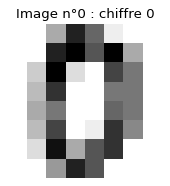

In [2]:
# Objectif : voir la première image sous deux formes : les nombres, puis le dessin.

print("Les 64 nombres de la première image, rangés en grille 8 × 8 :")
print(images[0].astype(int))
print("Le chiffre correspondant :", y[0])

plt.figure(figsize=(2.5, 2.5))
plt.imshow(images[0], cmap="gray_r")     # gray_r : 0 = blanc, 16 = noir
plt.title(f"Image n°0 : chiffre {y[0]}")
plt.axis("off")
plt.show()

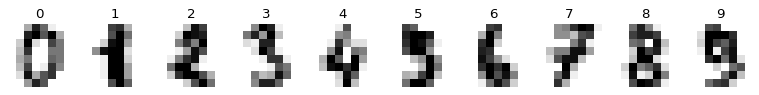

In [3]:
# Objectif : voir un exemple de chaque chiffre.

fig, axes = plt.subplots(1, 10, figsize=(12, 1.8))
for chiffre, ax in enumerate(axes):
    # np.where(y == chiffre)[0][0] donne la position de la première image de ce chiffre
    position = np.where(y == chiffre)[0][0]
    ax.imshow(images[position], cmap="gray_r")
    ax.set_title(chiffre)
    ax.axis("off")
plt.show()

**Lecture du résultat.** Les nombres de la grille montrent le dessin : **les pixels qui valent 0** forment le fond blanc, et les grandes valeurs dessinent le trait du chiffre. Au total, **49 % des pixels valent 0** dans le jeu de données : une grande partie de chaque image est du fond.

### À vous : une autre image

**À faire :** regardez l'image n°100 : affichez sa grille de nombres, comptez ses pixels à 0, puis dessinez-la.

**Questions :**
1. Quel chiffre est écrit sur cette image ?
2. Combien de pixels valent 0 ? Que représente la valeur la plus grande de la grille ?

[[ 0  0  0  2 13  0  0  0]
 [ 0  0  0  8 15  0  0  0]
 [ 0  0  5 16  5  2  0  0]
 [ 0  0 15 12  1 16  4  0]
 [ 0  4 16  2  9 16  8  0]
 [ 0  0 10 14 16 16  4  0]
 [ 0  0  0  0 13  8  0  0]
 [ 0  0  0  0 13  6  0  0]]
Pixels à 0 : 36 sur 64
Valeur la plus grande : 16.0
Chiffre indiqué par y : 4


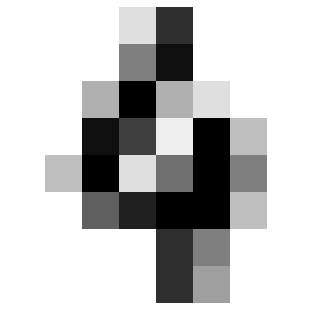

In [4]:
# Objectif : regarder l'image n°100.

indice = 100
image = images[indice]

# La grille de nombres de cette image
print(image.astype(int))

# On compte les pixels qui valent 0 : (image == 0) donne True/False, sum() compte les True
nb_zeros = (image == 0).sum()
print("Pixels à 0 :", nb_zeros, "sur", image.size)
print("Valeur la plus grande :", image.max())

# Le dessin de l'image
plt.imshow(image, cmap="gray_r")
plt.axis("off")
plt.show()
print("Chiffre indiqué par y :", y[indice])

### Réponse

1. L'image n°100 représente le chiffre **4**.
2. 36 pixels sur 64 valent 0 (le fond blanc). La valeur la plus grande est **16** : c'est la valeur maximale possible, un pixel entièrement noir, là où le trait du chiffre est le plus marqué.

# Partie 2 : Le perceptron, une somme pondérée

### Concept

**D'abord, qu'est-ce qu'un modèle ?** Un modèle est un programme qui **apprend à répondre à une question en regardant des exemples**, au lieu qu'on lui écrive toutes les règles à la main. On lui montre beaucoup d'images avec leur bonne réponse (leur étiquette) : c'est l'**entraînement**. Il en tire une règle. On lui donne ensuite des images qu'il n'a jamais vues, pour voir s'il trouve la bonne réponse : c'est la **prédiction**. Quand les bonnes réponses sont connues pendant l'entraînement, on parle d'**apprentissage supervisé**.

**Le perceptron** est un modèle de **classification** très simple : il choisit une catégorie pour chaque image. Il a été proposé par F. Rosenblatt en 1958 : [*The perceptron: a probabilistic model for information storage and organization in the brain*](https://doi.org/10.1037/h0042519), Psychological Review. Dans cette partie, il répond à une question à **deux réponses seulement** (« est-ce un 1 ? oui ou non »), ce qu'on appelle une classification **binaire**.

Il fait un **score** : on multiplie chaque nombre de l'image par un **poids**, on additionne tout, et on ajoute un nombre appelé **biais**.

> score = poids₁ × pixel₁ + poids₂ × pixel₂ + ... + poids₆₄ × pixel₆₄ + biais

Si le score est **positif**, le perceptron répond « 1 » ; sinon il répond « 0 ». Ici, « 1 » veut dire **oui** (l'image est de la catégorie cherchée) et « 0 » veut dire non.
**Les poids disent quels pixels comptent, et dans quel sens** : un poids positif pousse vers « 1 », un poids négatif pousse vers « 0 ».

La **frontière** est la limite entre les deux réponses : c'est le cas où le score vaut exactement 0. Pour une image donnée, il n'y a qu'un seul score : s'il est positif, la réponse est « 1 » ; s'il est négatif, la réponse est « 0 ». Un score exactement égal à 0 est pile sur la frontière. Par convention, dans ce TD, une image dont le score vaut 0 est considérée comme **n'étant pas dans la catégorie cherchée** : la réponse est « non ». C'est aussi le choix de scikit-learn, la bibliothèque utilisée plus bas : sa documentation indique qu'un score strictement supérieur à 0 prédit la classe 1 ([`decision_function` de `Perceptron`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Perceptron.html#sklearn.linear_model.Perceptron.decision_function)).

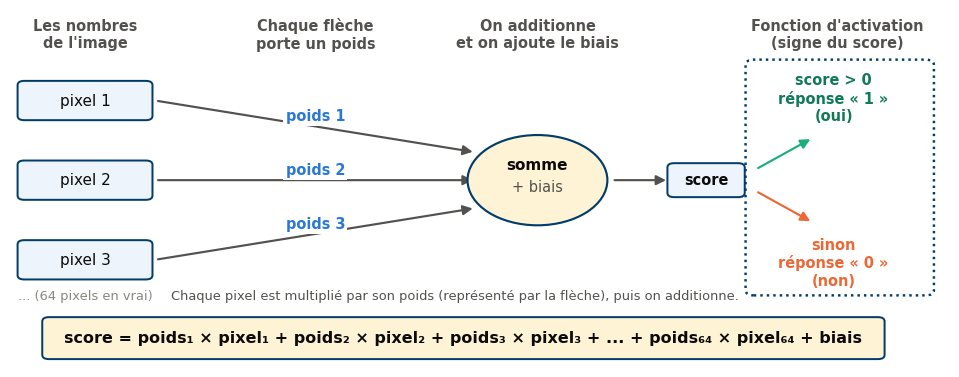

**La fonction d'activation.** Le perceptron travaille en deux temps. D'abord, il calcule le **score** : la somme des nombres multipliés par leurs poids, plus le biais. Ensuite, il transforme ce score en réponse avec une règle : « si le score est positif, la réponse est 1 (oui), sinon 0 (non) ». Cette règle s'appelle la **fonction d'activation**. C'est la partie entourée en pointillés sur le schéma. Ici, elle est très simple : elle regarde seulement le signe du score. Il existe d'autres fonctions d'activation, que nous n'utiliserons pas dans ce TD.

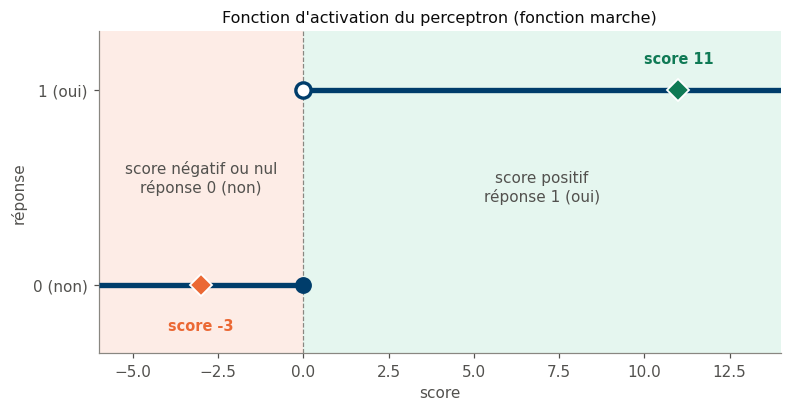

Ce graphique représente **la fonction d'activation** : en abscisse le score, en ordonnée la réponse. Le point plein en (0, 0) et le point vide en (0, 1) disent qu'un score exactement égal à 0 donne la réponse 0 (non). Les traits bleus montrent la réponse pour **tous les scores possibles**, pas seulement pour ceux de l'exemple : pour n'importe quel score, on lit la réponse sur la ligne, à la verticale. Les deux losanges (-3 et 11), eux, sont les scores de l'exemple ci-dessous.
On l'appelle **fonction marche** (en anglais *step function*) parce que son graphique ressemble à une marche d'escalier : la réponse passe d'un seul coup de 0 à 1 quand le score devient positif. Les mathématiciens l'appellent aussi **fonction de Heaviside**. La définition utilisée ici (1 si le nombre est strictement positif, 0 sinon) est celle de la bibliothèque de fonctions mathématiques du NIST (*National Institute of Standards and Technology*) : [*NIST Digital Library of Mathematical Functions*, section 1.16(iv), équation 1.16.13](https://dlmf.nist.gov/1.16).

**Exemple avec 2 pixels**: Les poids sont (1 ; -2) et le biais est 1. On veut **classer** l'image (2 ; 3), c'est-à-dire savoir si elle est dans la catégorie cherchée (réponse « oui », « 1 ») ou non (réponse « non », « 0 »). Ici, l'image n'a que 2 pixels, de valeurs 2 et 3 ; une vraie image en a 64.

| | pixel 1 | pixel 2 |
|---|---:|---:|
| valeur du pixel | 2 | 3 |
| poids | 1 | -2 |
| valeur × poids | 2 | -6 |

- On additionne les deux résultats : 2 + (-6) = -4.
- On ajoute le biais : -4 + 1 = **-3**. C'est le score.
- Le score est négatif : le perceptron répond « 0 ».

### Comment il apprend

Au début, tous les poids valent 0. On lui montre les exemples **un par un** :
- si sa réponse est **juste**, on ne change rien ;
- si elle est **fausse**, on corrige avec la règle suivante :
  - pour chaque pixel : poids du pixel ← poids du pixel + (vraie réponse - réponse donnée) × valeur du pixel ;
  - biais ← biais + (vraie réponse - réponse donnée).

Voici trois situations possibles, avec l'image (2 ; 3). Dans chacune, on compare la vraie réponse et la réponse donnée : la différence « vraie réponse - réponse donnée » ne peut valoir que **1**, **-1** ou **0**.

| Situation | Effet : le calcul |
|---|---|
| Poids (1 ; -2), biais 1, image (2 ; 3).<br>Score = 1 × 2 + (-2) × 3 + 1 = -3, donc réponse « non ».<br>Mais c'était « oui » : la réponse est fausse, **on corrige les poids**. | vraie réponse - réponse donnée = 1 - 0 = **1**<br>poids 1 : 1 + 1 × 2 = 3<br>poids 2 : -2 + 1 × 3 = 1<br>biais : 1 + 1 = 2<br>Nouveau score : 3 × 2 + 1 × 3 + 2 = **11** |
| Poids (3 ; 1), biais 2, image (2 ; 3).<br>Score = 3 × 2 + 1 × 3 + 2 = 11, donc réponse « oui ».<br>Mais c'était « non » : la réponse est fausse, **on corrige les poids**. | vraie réponse - réponse donnée = 0 - 1 = **-1**<br>poids 1 : 3 + (-1) × 2 = 1<br>poids 2 : 1 + (-1) × 3 = -2<br>biais : 2 + (-1) = 1<br>Nouveau score : 1 × 2 + (-2) × 3 + 1 = **-3** |
| Poids (3 ; 1), biais 2, image (2 ; 3).<br>Score = 11, donc réponse « oui ».<br>Et c'était « oui » : la réponse est juste, **on ne corrige rien**. | vraie réponse - réponse donnée = 1 - 1 = **0**<br>poids 1 : 3 + 0 × 2 = 3<br>poids 2 : 1 + 0 × 3 = 1<br>biais : 2 + 0 = 2<br>Rien ne change : le score reste **11** |

### Une époque (*epoch*)

Une **époque** est un passage complet sur **tous les exemples** du jeu d'apprentissage : le perceptron regarde chaque image une fois, et se corrige à chaque erreur. À la fin d'une époque, on compte les erreurs :
- s'il n'y en a aucune, l'apprentissage est terminé ;
- sinon, on recommence une nouvelle époque, en gardant les poids obtenus.

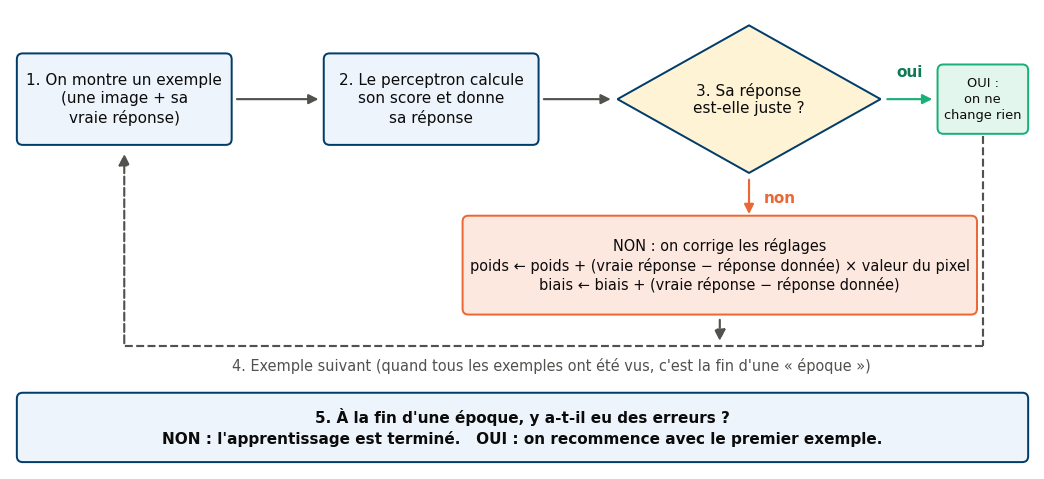

### Démo : le perceptron en quelques lignes

In [5]:
# Objectif : écrire l'apprentissage du perceptron (réponses possibles : 0 ou 1).

def texte_nombres(valeurs):
    # met une liste de nombres sous la forme (4, 4) : le format :g enlève le ".0" inutile
    return "(" + ", ".join(f"{v:g}" for v in valeurs) + ")"


def entrainer_perceptron(X, y, nb_epoques=20, detail_epoque=None):
    poids = np.zeros(X.shape[1])    # un poids par colonne, tous à 0 au départ
    biais = 0.0
    for epoque in range(1, nb_epoques + 1):
        erreurs = 0
        # detail_epoque : numéro de l'époque qu'on veut voir étape par étape (None : aucune)
        afficher = (epoque == detail_epoque)
        if afficher:
            print(f"Époque {epoque}, étape par étape :")
        for xi, yi in zip(X, y):    # on regarde les exemples un par un
            poids_avant, biais_avant = poids, biais   # l'état AVANT cet exemple
            # xi @ poids = poids₁ × valeur₁ + poids₂ × valeur₂ + ...
            score = xi @ poids + biais
            prediction = 1 if score > 0 else 0
            if prediction != yi:    # réponse fausse (« non » à tort ou « oui » à tort) : on corrige
                # à chaque réponse fausse, on met à jour tous les poids et le biais ; si la réponse est juste, rien ne change
                # mise à jour des poids : on ajoute (vraie réponse - réponse donnée) × la valeur de chaque pixel
                poids = poids + (yi - prediction) * xi
                # mise à jour du biais : on ajoute seulement (vraie réponse - réponse donnée), sans multiplier par un pixel
                biais = biais + (yi - prediction)
                erreurs += 1
            if afficher:            # affichage de l'état avant, du score, de la réponse, puis de l'état après
                verdict = "juste" if prediction == yi else "FAUSSE, on corrige"
                debut = f"  {texte_nombres(xi)}, vraie réponse {yi} "
                print(f"{debut}| AVANT : poids {texte_nombres(poids_avant)}, biais {biais_avant:g} -> score {score:g} -> réponse {prediction} : {verdict}")
                print(f"{' ' * len(debut)}| APRÈS : poids {texte_nombres(poids)}, biais {biais:g}")
        print(f"Époque {epoque} : {erreurs} erreur(s)")
        if erreurs == 0:            # plus aucune erreur : l'apprentissage est terminé
            break
    return poids, biais


# Un petit exemple à 2 colonnes : 4 points de la classe 0 en bas à gauche, 4 de la classe 1 en haut à droite
X_petit = np.array([[1, 1], [2, 1], [1, 2], [2, 2], [4, 4], [5, 4], [4, 5], [5, 5]], dtype=float)
y_petit = np.array([0, 0, 0, 0, 1, 1, 1, 1])

# detail_epoque=1 : on affiche la première époque étape par étape (poids et biais avant et après chaque exemple)
poids_petit, biais_petit = entrainer_perceptron(X_petit, y_petit, detail_epoque=1)
print("Poids :", poids_petit, " Biais :", biais_petit)

Époque 1, étape par étape :
  (1, 1), vraie réponse 0 | AVANT : poids (0, 0), biais 0 -> score 0 -> réponse 0 : juste
                          | APRÈS : poids (0, 0), biais 0
  (2, 1), vraie réponse 0 | AVANT : poids (0, 0), biais 0 -> score 0 -> réponse 0 : juste
                          | APRÈS : poids (0, 0), biais 0
  (1, 2), vraie réponse 0 | AVANT : poids (0, 0), biais 0 -> score 0 -> réponse 0 : juste
                          | APRÈS : poids (0, 0), biais 0
  (2, 2), vraie réponse 0 | AVANT : poids (0, 0), biais 0 -> score 0 -> réponse 0 : juste
                          | APRÈS : poids (0, 0), biais 0
  (4, 4), vraie réponse 1 | AVANT : poids (0, 0), biais 0 -> score 0 -> réponse 0 : FAUSSE, on corrige
                          | APRÈS : poids (4, 4), biais 1
  (5, 4), vraie réponse 1 | AVANT : poids (4, 4), biais 1 -> score 37 -> réponse 1 : juste
                          | APRÈS : poids (4, 4), biais 1
  (4, 5), vraie réponse 1 | AVANT : poids (4, 4), biais 1 -> score 37 

Pour une image de 64 pixels, c'est exactement la même chose, avec 64 poids au lieu de 2 : le calcul reste le même.

### Un jeu de test pour être honnête

Un modèle qui réussit sur les images qu'il a vues pour apprendre n'a rien prouvé : il a peut-être seulement tout mémorisé. On **cache donc une partie des images** (ici 25 %) : le **jeu de test**. Le modèle apprend sur les 75 % restants (le **jeu d'apprentissage**), puis on le juge sur le test.

**Les proportions ne sont pas une règle : c'est un choix de découpage.** Dans ce TD, on prend 75 % pour apprendre et 25 % pour tester. On utilise aussi 80 % / 20 %, ou un découpage en trois paquets, par exemple 70 % pour apprendre, 20 % pour tester et 10 % pour la **validation**.

**À quoi sert le jeu de validation ?** Parfois, on hésite entre plusieurs versions d'un même modèle, par exemple entraîné pendant 5, 10 ou 50 époques. Pour choisir la meilleure, il faut les comparer sur des images. Si on les comparait sur le jeu de test, il ne serait plus caché. On compare donc les versions sur le jeu de validation, on garde la meilleure, puis, **une fois cette version gardée**, on mesure sa précision sur le jeu de test. L'image à retenir :
- le **jeu d'apprentissage** est le cours et ses exercices : le modèle apprend dessus ;
- le **jeu de validation** est l'examen blanc : on s'en sert pour comparer les versions du modèle et garder la meilleure ;
- le **jeu de test** est l'examen final : **on ne le regarde qu'après avoir gardé la meilleure version.**

L'ordre est donc toujours le même : **apprendre, puis valider, puis tester.**

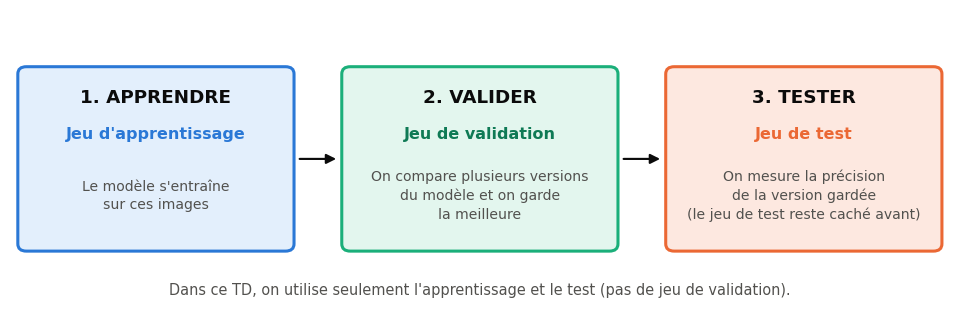

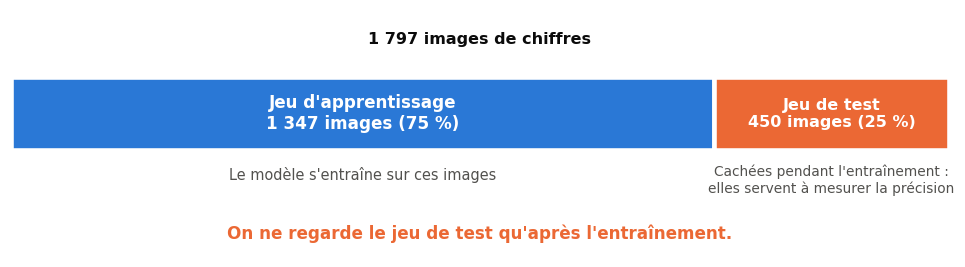

### Démo : 0 contre 1

On entraîne le perceptron à distinguer les chiffres 0 et 1. Pour séparer les images en deux paquets, on utilise la fonction `train_test_split` de scikit-learn ([documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)). Elle a trois réglages à connaître :
- `test_size=0.25` : 25 % des images vont dans le jeu de test ;
- `stratify` : chaque chiffre est aussi fréquent dans l'apprentissage que dans le test. Sans lui, un chiffre pourrait être rare dans le test, par hasard ;
- `random_state=42` : la fonction mélange les images au hasard. Avec ce nombre, le mélange est toujours le même, donc tout le monde trouve les mêmes résultats. Le nombre lui-même n'a pas d'importance : 7 ou 100 marchent aussi.

In [6]:
# Objectif : apprendre à distinguer les chiffres 0 et 1.
from sklearn.model_selection import train_test_split

# On garde seulement les images de 0 et de 1 ( | veut dire "ou")
masque = (y == 0) | (y == 1)
X01, y01 = X[masque], y[masque]

# test_size=0.25 : 25 % des images pour le test
# stratify=y01 : même proportion de 0 et de 1 dans les deux paquets
# random_state=42 : fixe le tirage au hasard, pour que tout le monde ait les mêmes paquets
X_app, X_test, y_app, y_test = train_test_split(X01, y01, test_size=0.25, random_state=42, stratify=y01)

# On entraîne le perceptron sur le jeu d'apprentissage
poids01, biais01 = entrainer_perceptron(X_app, y_app)

# Prédiction sur le test : la réponse est 1 si le score est positif, sinon 0
predictions = (X_test @ poids01 + biais01 > 0).astype(int)
# Précision = part des réponses justes
precision = (predictions == y_test).mean()
print("Précision sur le test :", precision, "sur", len(y_test), "images")

Époque 1 : 13 erreur(s)
Époque 2 : 0 erreur(s)
Précision sur le test : 1.0 sur 90 images


### Questions

1. Combien d'époques ont été nécessaires ?
2. Quelle précision obtenez-vous sur le jeu de test ? Est-ce étonnant ?
3. Remplacez `random_state=42` par `random_state=7`, puis relancez la cellule. Qu'est-ce qui change ?
4. Comparez avec le résultat obtenu avec 42. Quelle conclusion en tirez-vous ?

### Réponse

1. Il faut **2 époques** : 13 erreur(s) à la première, puis 0 à la dernière.
2. La précision sur le test est de **100 %** (90 images sur 90). Ce n'est pas étonnant : un 0 est un anneau et un 1 est un trait. Les deux dessins sont très différents. On dit que ces deux classes sont **séparables par une droite**. On peut tracer une frontière droite qui laisse les images d'une classe d'un côté et celles de l'autre classe de l'autre côté. Avec 64 colonnes, on ne peut pas la dessiner, mais l'idée est la même. Le perceptron ne réussit à coup sûr que dans ce cas.
3. Le tirage au hasard change, donc les paquets changent. Les résultats peuvent changer un peu : avec `random_state=7`, il faut **3 époques** et la précision sur le test est de **100 %**. C'est pour cela qu'on fixe `random_state` : tout le monde obtient les mêmes résultats.
4. Avec 7, il faut **3 époques** au lieu de 2, mais la précision reste de **100 %**. Ici, le tirage change donc seulement le nombre d'époques. Les 0 et les 1 sont faciles à distinguer, donc la précision ne bouge pas. **Conclusion :** le tirage peut changer le résultat. Pour comparer deux modèles, il faut garder le même `random_state`. Sinon, on ne sait pas si la différence vient du modèle ou du tirage.

### Démo : que regarde le perceptron ?

Chacun des 64 poids correspond à un pixel. On peut donc **dessiner les poids** comme une image 8 × 8 : en bleu, les pixels dont le poids est positif (ils poussent vers « 1 »), en rouge ceux dont le poids est négatif (ils poussent vers « 0 »).

Époque 1 : 4 erreur(s)
Époque 2 : 2 erreur(s)
Époque 3 : 0 erreur(s)


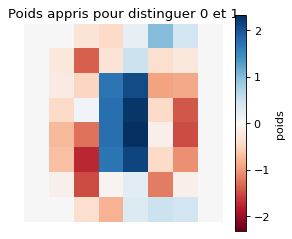

In [7]:
# Objectif : dessiner les 64 poids sous forme d'image 8 × 8.

# Pour que cette démo fonctionne seule, on réentraîne sur toutes les images de 0 et de 1
masque_01 = (y == 0) | (y == 1)
poids_demo, biais_demo = entrainer_perceptron(X[masque_01], y[masque_01])

grille_poids = poids_demo.reshape(8, 8)   # reshape remet les 64 poids en grille 8 × 8
limite = np.abs(grille_poids).max()       # pour que le blanc corresponde bien au poids 0

plt.figure(figsize=(4, 3.5))
plt.imshow(grille_poids, cmap="RdBu", vmin=-limite, vmax=limite)
plt.colorbar(label="poids")
plt.title("Poids appris pour distinguer 0 et 1")
plt.axis("off")
plt.show()

**Lecture du résultat.**
- Les poids **positifs** (bleu foncé) sont regroupés **au centre** de l'image, là où passe le trait vertical d'un 1.
- Les poids **négatifs** (rouge) **entourent** ce centre, là où passe l'anneau d'un 0.
- Les pixels du bord, presque toujours blancs, ont un poids proche de 0 : ils n'aident pas à décider.

Le perceptron a donc appris tout seul que « du noir au centre veut dire 1 » et « du noir sur les côtés veut dire 0 ». C'est cette lecture des poids qui rend un modèle simple **explicable**.

# Partie 3 : Classer les dix chiffres

### Concept

Avec dix chiffres, une réponse « oui ou non » ne suffit plus. La méthode habituelle est « **un contre tous** » : on entraîne **dix perceptrons**, un par chiffre (« est-ce un 3 ? », « est-ce un 7 ? »...). Pour une image, chacun donne son score, et la réponse est le chiffre dont le score est **le plus grand**.

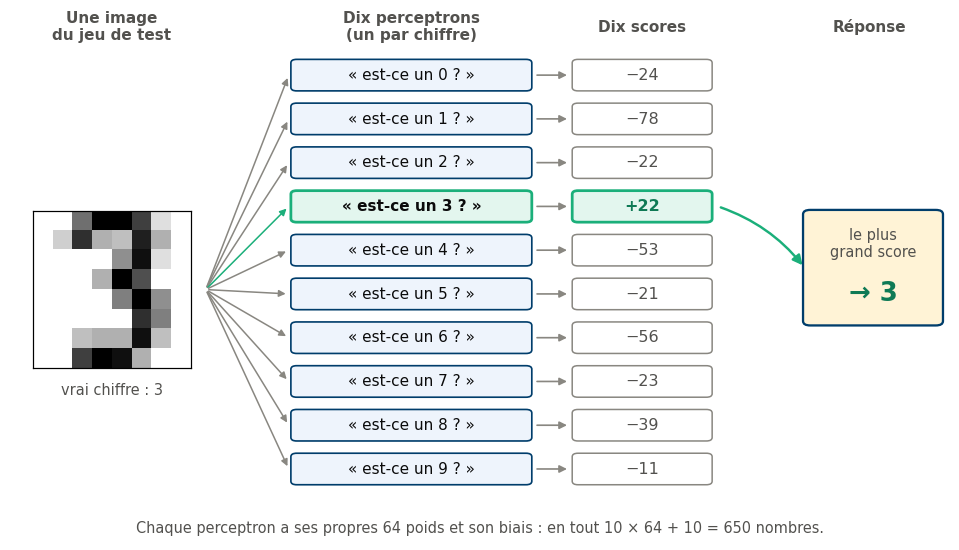

Un score positif veut dire « oui, c'est mon chiffre », un score négatif veut dire « non ». Si plusieurs perceptrons disent oui, on garde le plus grand score.

`scikit-learn` fait tout cela pour nous avec `Perceptron`. Un seul objet `Perceptron` contient les dix perceptrons. On garde le même découpage apprentissage / test : 75 % des images pour apprendre, 25 % pour juger.

Référence : [le `Perceptron` de scikit-learn](https://scikit-learn.org/stable/modules/linear_model.html#perceptron) (guide utilisateur).

### Démo

In [8]:
# Objectif : entraîner dix perceptrons (un par chiffre), puis juger leurs réponses sur le jeu de test.
from sklearn.linear_model import Perceptron
from sklearn.model_selection import train_test_split

# test_size=0.25 : 25 % des images sont gardées pour le test (c'est un choix : 0.2 ou 0.3 sont possibles aussi)
# stratify=y : chaque chiffre est présent dans les mêmes proportions dans l'apprentissage et le test
X_app, X_test, y_app, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# max_iter : nombre maximal d'époques ; random_state : fixe le hasard pour retrouver les mêmes résultats
modele = Perceptron(max_iter=1000, random_state=42)
modele.fit(X_app, y_app)

# score() donne la précision : la part des images dont le chiffre est bien trouvé
print("Précision sur l'apprentissage :", round(modele.score(X_app, y_app), 3), "sur", len(y_app), "images")
print("Précision sur le test         :", round(modele.score(X_test, y_test), 3), "sur", len(y_test), "images")

Précision sur l'apprentissage : 0.961 sur 1347 images
Précision sur le test         : 0.947 sur 450 images


### Questions

1. Quelle est la précision sur l'apprentissage ? Et sur le test ?
2. Pourquoi est-elle un peu plus basse sur le test ?

### Réponse

1. La précision est de **96,1 %** sur l'apprentissage (1347 images) et de **94,7 %** sur le test (450 images).
2. Les images du test sont des images que le modèle n'a jamais vues. Il se trompe un peu plus que sur celles qu'il a apprises.

Le modèle n'est pas parfait : sur 450 images de test, il se trompe **24 fois**. Mais **où** se trompe-t-il ? C'est ce que montre la matrice de confusion.

### La matrice de confusion

Une **matrice de confusion** est un tableau : chaque **ligne** est le vrai chiffre, chaque **colonne** est le chiffre prédit. La case (3 ; 8) compte les images qui étaient des 3 et que le modèle a prises pour des 8. Les bonnes réponses sont sur la **diagonale** ; tout le reste est une erreur.

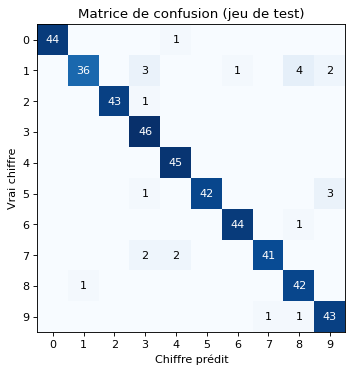

In [9]:
# Objectif : voir quels chiffres le perceptron confond.
from sklearn.metrics import confusion_matrix

predictions = modele.predict(X_test)                    # le chiffre prédit pour chaque image de test
matrice = confusion_matrix(y_test, predictions)         # lignes = vrai chiffre, colonnes = chiffre prédit

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(matrice, cmap="Blues")
for i in range(10):
    for j in range(10):
        # on écrit le nombre d'images dans chaque case, sauf les cases vides pour alléger le dessin
        if matrice[i, j] > 0:
            ax.text(j, i, matrice[i, j], ha="center", va="center",
                    color="white" if matrice[i, j] > 25 else "black")
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xlabel("Chiffre prédit")
ax.set_ylabel("Vrai chiffre")
ax.set_title("Matrice de confusion (jeu de test)")
plt.show()

**Exemple de lecture.** Regardons la ligne du 5 : sur les 46 images de 5, le modèle prédit « 5 » 42 fois (la diagonale). Il prédit « 9 » au lieu de « 5 » 3 fois, et « 3 » au lieu de « 5 » 1 fois.

Nombre d'erreurs : 24


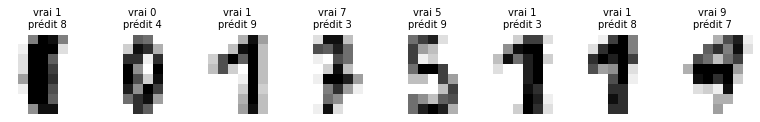

In [10]:
# Objectif : regarder des images que le perceptron a mal classées.

erreurs = np.where(predictions != y_test)[0]            # positions des images mal classées
print("Nombre d'erreurs :", len(erreurs))

# images_test : les images 8 × 8 du jeu de test (même découpage que X_test, grâce au même random_state)
_, images_test = train_test_split(images, test_size=0.25, random_state=42, stratify=y)

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, position in zip(axes, erreurs[:8]):
    ax.imshow(images_test[position], cmap="gray_r")
    ax.set_title(f"vrai {y_test[position]}\nprédit {predictions[position]}", fontsize=9)
    ax.axis("off")
plt.show()

### À vous : lire les erreurs

**À faire :** calculez le nombre d'erreurs, puis trouvez dans la matrice de confusion la confusion la plus fréquente (un vrai chiffre pris pour un autre).

**Questions :**
1. Combien d'erreurs le modèle fait-il ? Quelle est la confusion la plus fréquente ?
2. Les chiffres 3 et 4 ont-ils tous été reconnus ? Quel chiffre est le plus souvent mal reconnu, et pourquoi, à votre avis ? (Regardez les images mal classées de la démo.)

In [11]:
# Objectif : compter les erreurs et trouver la confusion la plus fréquente.

# Nombre d'erreurs : nombre d'images où la prédiction est différente du vrai chiffre
nb_erreurs = (predictions != y_test).sum()
print("Nombre d'erreurs :", nb_erreurs)

# On met la diagonale à 0 : il ne reste que les erreurs
erreurs_seules = matrice.copy()
np.fill_diagonal(erreurs_seules, 0)

# np.unravel_index transforme la position de la plus grande case en (ligne, colonne)
vrai, predit = np.unravel_index(erreurs_seules.argmax(), erreurs_seules.shape)
print("Confusion la plus fréquente : des", vrai, "pris pour des", predit)
print("Nombre de fois :", erreurs_seules.max())

Nombre d'erreurs : 24
Confusion la plus fréquente : des 1 pris pour des 8
Nombre de fois : 4


### Réponse

1. Le modèle fait **24 erreurs** sur 450 images. La confusion la plus fréquente est celle des **1 pris pour des 8** (4 fois). Les 1 sont aussi pris pour des 3 (3 fois) et des 9 (2 fois).
2. Les chiffres 3 et 4 sont tous reconnus (46 sur 46 et 45 sur 45). Le chiffre le plus souvent mal reconnu est le **1** : 10 erreurs sur 46 images, prises pour des 3, des 6, des 8 ou des 9. Sur les 8 erreurs affichées dans la démo, 4 sont des 1, écrits avec un trait épais ou avec un petit drapeau en haut : ils ont plus de pixels noirs qu'un 1 « simple » et ressemblent alors à des chiffres plus chargés. C'est une **explication plausible**, pas une preuve : le perceptron ne fait qu'une somme pondérée de pixels, et le jeu contient des 1 écrits de façons très différentes. Pour la vérifier, il faudrait regarder toutes les erreurs, pas seulement huit.

# Partie 4 : Que contient un modèle appris ?

### Concept

On a dit qu'on **entraîne** un modèle, et que le modèle est **appris** quand l'entraînement est fini. Mais qu'a-t-il appris, concrètement ? Réponse : des **nombres**.

- Un **paramètre** est un nombre que le modèle règle lui-même pendant l'entraînement. Pour le perceptron, ce sont les **poids** et le **biais**.
- Un **modèle appris** est le calcul du perceptron (la somme pondérée, puis la fonction d'activation) avec ses **poids et son biais** réglés par l'entraînement. Si on garde ces nombres, on peut refaire des prédictions sans refaire l'entraînement.
- À ne pas confondre avec les **réglages choisis avant l'entraînement** (par exemple le nombre maximal d'époques) : c'est nous qui les fixons, le modèle ne les règle pas.

### Démo : les paramètres du modèle des dix chiffres

In [12]:
# Objectif : voir les paramètres du modèle appris dans la partie 3 (le perceptron des dix chiffres).

# modele.coef_ contient les poids : une ligne par perceptron (un par chiffre), une colonne par pixel
print("Nombre de perceptrons :", modele.coef_.shape[0])
print("Nombre de poids par perceptron :", modele.coef_.shape[1])

# modele.intercept_ contient les biais : un biais par perceptron
print("Nombre de biais :", modele.intercept_.size)

# Nombre total de paramètres = tous les poids + tous les biais
nb_parametres = modele.coef_.size + modele.intercept_.size
print("Nombre de paramètres :", nb_parametres)
print("Calcul :", modele.coef_.shape[0], "×", modele.coef_.shape[1], "+", modele.intercept_.size, "=", nb_parametres)

# Les 5 premiers poids du perceptron du chiffre 3 (un poids par pixel)
print("Les 5 premiers poids du perceptron du chiffre 3 :", modele.coef_[3][:5].round(2))

Nombre de perceptrons : 10
Nombre de poids par perceptron : 64
Nombre de biais : 10
Nombre de paramètres : 650
Calcul : 10 × 64 + 10 = 650
Les 5 premiers poids du perceptron du chiffre 3 : [ 0.    0.25 -5.62  0.31 12.69]


`scikit-learn` utilise la méthode « un contre tous » (en anglais *one versus all*). Il crée un perceptron par chiffre.

### Démo : refaire une prédiction avec les seuls nombres du modèle

Voici les nombres des dix perceptrons : pour chacun, son biais et ses 64 poids. On n'affiche que les 5 premiers poids. Pour le chiffre 3, on affiche les 64 poids en grille 8 × 8. Avec ces nombres seuls, on retrouve la prédiction du modèle, sans refaire l'entraînement.

In [13]:
# Objectif : afficher les nombres des dix perceptrons (le modèle appris), puis refaire une prédiction avec eux seuls.

# Pour chaque perceptron : son biais et ses 5 premiers poids (il en a 64 en tout)
for chiffre in range(10):
    print("Perceptron du", chiffre, ": biais", modele.intercept_[chiffre].round(1), "; poids", modele.coef_[chiffre][:5].round(1), "...")

# Les 64 poids du perceptron du chiffre 3, en grille 8 × 8 (une case par pixel)
print("Les 64 poids du perceptron du chiffre 3 :")
print(modele.coef_[3].reshape(8, 8).round(1))

# Une image du jeu de test : on calcule les dix scores à la main
image = X_test[1]
scores = modele.coef_ @ image + modele.intercept_        # un score par chiffre : somme pondérée + biais

# argmax donne le chiffre dont le score est le plus grand
print("Chiffre trouvé avec les nombres seuls :", scores.argmax())
print("Chiffre prédit par le modèle          :", modele.predict([image])[0])
print("Vrai chiffre                          :", y_test[1])

Perceptron du 0 : biais -4.0 ; poids [ 0.  -0.9 -1.4  1.6 -0.5] ...
Perceptron du 1 : biais -36.0 ; poids [  0.   -1.1   1.2   5.  -22.9] ...
Perceptron du 2 : biais -4.0 ; poids [ 0.   0.   2.  -1.2 -1.9] ...
Perceptron du 3 : biais -7.0 ; poids [ 0.   0.2 -5.6  0.3 12.7] ...
Perceptron du 4 : biais 3.0 ; poids [ 0.  -0.8 -2.9 -9.8 -6.4] ...
Perceptron du 5 : biais -7.0 ; poids [ 0.   1.9 10.8 -5.6  2.1] ...
Perceptron du 6 : biais -9.0 ; poids [ 0.  -1.2 -6.6 -2.9 -3. ] ...
Perceptron du 7 : biais -4.0 ; poids [ 0.  -2.   3.2  2.1  1.9] ...
Perceptron du 8 : biais -24.0 ; poids [ 0.   0.1  1.3 -8.8 -1.2] ...
Perceptron du 9 : biais -21.0 ; poids [ 0.  -3.6 -4.6  6.9 -2.2] ...
Les 64 poids du perceptron du chiffre 3 :
[[  0.    0.2  -5.6   0.3  12.7   1.7  -3.2  -1.6]
 [  0.   -2.6   5.6   5.4   3.4   5.5  12.2  -1.4]
 [ -0.1  -1.2 -13.9 -13.2   6.8  -5.6   1.9  -0.6]
 [  0.   -6.1 -12.4  -2.4   3.9 -15.8 -15.7   0. ]
 [  0.   -3.6  -4.6   0.4   4.   -2.3  -4.8   0. ]
 [  0.    1.6  -

Ces 650 nombres (10 × 64 poids et 10 biais) sont ce qu'on appelle le **modèle appris**. Pour refaire une prédiction, on n'a pas besoin d'autre chose.

### Démo : utiliser le modèle appris

Un modèle appris sert à **prédire**. On lui donne des images avec `modele.predict`, et il répond un chiffre par image. Voici cinq images du jeu de test, avec la prédiction du modèle et le vrai chiffre.

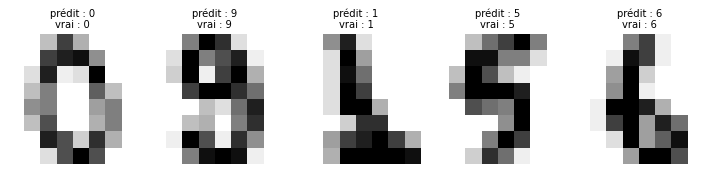

In [14]:
# Objectif : utiliser le modèle appris sur des images du jeu de test, et comparer sa prédiction au vrai chiffre.

numeros_images = [1, 2, 3, 4, 5]    # les numéros de cinq images du jeu de test (il y en a 450, de 0 à 449)

# predict utilise les poids et les biais rangés dans modele ; X_test[numeros_images] ne contient que les images
# Un tableau de 5 images donne 5 prédictions d'un coup, sans boucle
predictions_cinq_images = modele.predict(X_test[numeros_images])

fig, axes = plt.subplots(1, 5, figsize=(9, 2.4))
for ax, numero, prediction in zip(axes, numeros_images, predictions_cinq_images):
    ax.imshow(images_test[numero], cmap="gray_r")    # images_test : les images 8 × 8 du jeu de test
    ax.set_title(f"prédit : {prediction}\nvrai : {y_test[numero]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

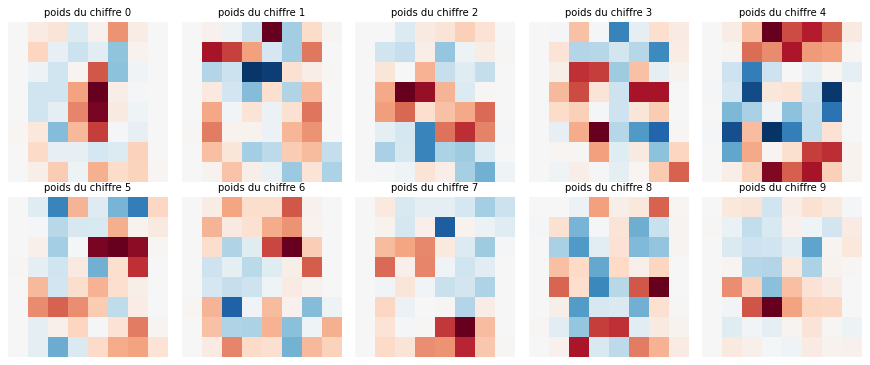

In [15]:
# Objectif : dessiner les poids de chaque chiffre sous forme d'image 8 × 8 (une "carte" par chiffre).

fig, axes = plt.subplots(2, 5, figsize=(11, 4.6))
for chiffre, ax in enumerate(axes.ravel()):
    # reshape remet les 64 poids du chiffre en grille 8 × 8
    carte = modele.coef_[chiffre].reshape(8, 8)
    limite = np.abs(carte).max()             # chaque carte a sa propre échelle, avec le blanc pour le poids 0
    ax.imshow(carte, cmap="RdBu", vmin=-limite, vmax=limite)
    ax.set_title(f"poids du chiffre {chiffre}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Lecture du résultat.** Les dix cartes ne ressemblent pas à des chiffres lisibles : chaque perceptron ne cherche pas à reproduire son chiffre, mais les pixels qui l'aident à le distinguer des neuf autres. En **bleu**, un poids positif (le pixel pousse vers ce chiffre) ; en **rouge**, un poids négatif (le pixel pousse contre). Chaque carte a sa propre échelle de couleurs : on ne compare donc pas l'intensité des couleurs d'une carte à l'autre.

### À vous : et avec des images plus grandes ?

**MNIST** est un jeu célèbre de 60 000 images d'entraînement et 10 000 images de test, de **28 × 28 pixels** ([documentation de Keras](https://keras.io/api/datasets/mnist/)). On entraîne le même perceptron : un perceptron par chiffre, chacun avec un poids par pixel et un biais.

**À faire :** calculez le nombre de pixels d'une image de 28 × 28, puis le nombre de paramètres du modèle.

**Question :** combien de fois plus de paramètres que pour nos images de 8 × 8 ?

In [16]:
# Objectif : compter les paramètres du même perceptron sur des images de 28 × 28 pixels (MNIST).

# Nombre de pixels d'une image de 28 × 28
nb_pixels = 28 * 28

# Un perceptron par chiffre, chacun avec un poids par pixel et un biais :
# nombre de paramètres = 10 × nb_pixels (les poids) + 10 (les biais)
nb_parametres_mnist = 10 * nb_pixels + 10

print("Pixels par image :", nb_pixels)
print("Paramètres pour MNIST :", nb_parametres_mnist)

Pixels par image : 784
Paramètres pour MNIST : 7850


### Réponse

Une image de 28 × 28 a 28 × 28 = **784 pixels**. Chaque chiffre a donc 784 poids, ce qui fait 10 × 784 = 7 840 poids, plus 10 biais : **7 850 paramètres**. C'est environ **12 fois plus** que pour nos images de 8 × 8 (650 paramètres), avec exactement le même modèle. Plus les images sont grandes, plus il y a de nombres à régler.

**Au TD 6**, on fait l'inverse : on n'a plus les bonnes réponses, et on cherche des groupes d'images qui se ressemblent.